# 03 Topic Modeling

In [62]:
!pip install wordcloud

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import (
    ENGLISH_STOP_WORDS,
    CountVectorizer,
    TfidfVectorizer
)
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from wordcloud import WordCloud


### Load the cleaned dataset

In [2]:
df = pd.read_parquet("clean_news_final_project.parquet")

print(df.shape)
df.head()

(115006, 10)


,url,date,language,domain,title,content_raw,raw_len,text_clean,clean_len,has_residual_boilerplate
0,https://boingboing.net/2024/07/01/this-ai-vide...,2024-07-01,en,boingboing.net,This AI video of gymnastics might be the freak...,This AI video of gymnastics might be the freak...,5659,This AI video of gymnastics might be the freak...,2615,False
1,https://boingboing.net/2024/09/18/if-using-ai-...,2024-09-22,en,boingboing.net,"If using AI feels like a chore, try this - Boi...","If using AI feels like a chore, try this - Boi...",5930,"If using AI feels like a chore, try this - Boi...",3767,False
2,https://clickup.com/ai/prompts/business-risk-m...,2024-03-13,en,clickup.com,Best AI Prompts for Business Risk Management,Best AI Prompts for Business Risk Management\n...,8373,Harness the power of ClickUp AI to make smarte...,2403,False
3,https://crooksandliars.com/2025/12/state-ags-w...,2025-12-15,en,crooksandliars.com,State AGs Warn AI Companies: Clean Up Your Chi...,State AGs Warn AI Companies: Clean Up Your Chi...,7305,State AGs Warn AI Companies: Clean Up Your Chi...,3833,False
4,https://dbtnews.com/2023/07/26/bullfrog-ai-hol...,2023-07-26,en,dbtnews.com,Bullfrog AI Holdings Inc. [BFRG] Revenue clock...,Bullfrog AI Holdings Inc. [BFRG] Revenue clock...,5193,Bullfrog AI Holdings Inc. [BFRG] Revenue clock...,2266,False


### Combine title and cleaned text

In [3]:
df["article_text"] = (
    df["title"].fillna("").astype(str) + ". " +
    df["text_clean"].fillna("").astype(str)
)

df["article_text_len"] = df["article_text"].str.len()

df[["title", "text_clean", "article_text", "article_text_len"]].head()

,title,text_clean,article_text,article_text_len
0,This AI video of gymnastics might be the freak...,This AI video of gymnastics might be the freak...,This AI video of gymnastics might be the freak...,2695
1,"If using AI feels like a chore, try this - Boi...","If using AI feels like a chore, try this - Boi...","If using AI feels like a chore, try this - Boi...",3823
2,Best AI Prompts for Business Risk Management,Harness the power of ClickUp AI to make smarte...,Best AI Prompts for Business Risk Management. ...,2449
3,State AGs Warn AI Companies: Clean Up Your Chi...,State AGs Warn AI Companies: Clean Up Your Chi...,State AGs Warn AI Companies: Clean Up Your Chi...,3913
4,Bullfrog AI Holdings Inc. [BFRG] Revenue clock...,Bullfrog AI Holdings Inc. [BFRG] Revenue clock...,Bullfrog AI Holdings Inc. [BFRG] Revenue clock...,2379


### Article length statistics

In [4]:
df["article_text_len"].describe()

count    115006.000000
mean       3527.168661
std        2948.811217
min         310.000000
25%        1847.000000
50%        2867.000000
75%        4467.000000
max      139389.000000
Name: article_text_len, dtype: float64

### Word frequency exploration (sample)

In [5]:
sample_text = df["article_text"].sample(5000, random_state=42)

cv = CountVectorizer(
    stop_words="english",
    max_features=1000
)

X_cv = cv.fit_transform(sample_text)

words = cv.get_feature_names_out()
freq = X_cv.sum(axis=0).A1

word_freq_df = pd.DataFrame({
    "word": words,
    "freq": freq
}).sort_values("freq", ascending=False)

word_freq_df.head(50)

,word,freq
62,ai,44399
608,new,8424
250,data,8157
894,technology,6134
787,said,6069
475,intelligence,5135
562,market,4895
197,company,4448
531,like,4300
168,chatgpt,4232


The most frequent words include terms such as *ai*, *data*, *technology*, *company*, and *chatgpt*. While some of these words are central to the topic of the corpus, extremely frequent words may dominate the feature space and reduce the effectiveness of clustering.

Based on this analysis, we construct a custom stopword list in the next step to remove overly common or uninformative terms.

In [6]:
custom_stopwords = {
    "ai", "artificial", "intelligence", "technology", "tech",
    "said", "new", "use", "using", "time", "year",
    "people", "like", "just", "make", "help", "real",
    "based", "information", "content", "world", "news",
    "com", "2023", "2024", "2025",
    "article", "articles"
}

stopwords = list(ENGLISH_STOP_WORDS.union(custom_stopwords))

len(stopwords)

346

The final stopword list contains **346 terms**, which will be removed during TF-IDF feature extraction to improve topic separability.

### TF-IDF Feature Extraction

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    stop_words=stopwords,
    max_features=20000,
    min_df=20,
    max_df=0.8,
    ngram_range=(1,2)
)

X = tfidf.fit_transform(df["article_text"])

print(X.shape)

(115006, 20000)


In [ ]:
sample_size = 10000
np.random.seed(42)
sample_idx = np.random.choice(X.shape[0], sample_size, replace=False)
X_sample = X[sample_idx]

scores = []

for k in range(10, 21):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_sample)
    score = silhouette_score(X_sample, labels)
    scores.append((k, score))
    print(f"k={k}, silhouette={score:.4f}")

scores

k=10, silhouette=0.0115
k=11, silhouette=0.0132
k=12, silhouette=0.0132
k=13, silhouette=0.0133
k=14, silhouette=0.0140
k=15, silhouette=0.0145
k=16, silhouette=0.0147
k=17, silhouette=0.0154
k=18, silhouette=0.0158
k=19, silhouette=0.0173
k=20, silhouette=0.0176


[(10, 0.011505574569053555),
 (11, 0.013187664079633845),
 (12, 0.013215891322814326),
 (13, 0.013347210136019765),
 (14, 0.013981618590612359),
 (15, 0.014454341516227294),
 (16, 0.014730623835476004),
 (17, 0.015436192919325522),
 (18, 0.015803877699781168),
 (19, 0.01733262779491783),
 (20, 0.017600293882467453)]

The silhouette score increases gradually as the number of clusters grows from 10 to 20. Although the absolute values remain low, this is expected for sparse, high-dimensional TF-IDF document representations. Among the tested values, **K = 20** produces the highest silhouette score and is therefore selected for the final clustering step.

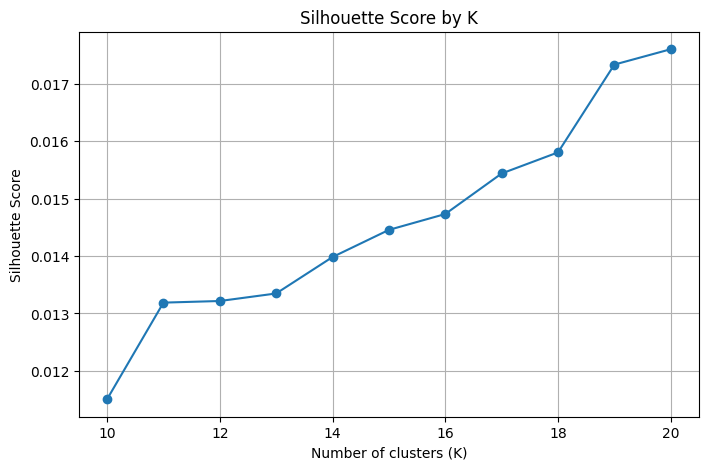

In [9]:
k_vals = [k for k, s in scores]
s_vals = [s for k, s in scores]

plt.figure(figsize=(8, 5))
plt.plot(k_vals, s_vals, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score by K")
plt.grid(True)
plt.show()

The plot shows a generally increasing trend in silhouette score as K increases. Since the highest score is obtained at **K = 20**, this value is used in the final KMeans model. This choice balances clustering performance with interpretability.

### Final KMeans clustering on full dataset

In [10]:
best_k = 20

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=20
)

df["topic_id"] = kmeans.fit_predict(X)

df[["title", "topic_id"]].head()

,title,topic_id
0,This AI video of gymnastics might be the freak...,6
1,"If using AI feels like a chore, try this - Boi...",6
2,Best AI Prompts for Business Risk Management,10
3,State AGs Warn AI Companies: Clean Up Your Chi...,9
4,Bullfrog AI Holdings Inc. [BFRG] Revenue clock...,1


### Extract top keywords per cluster

In [11]:
terms = tfidf.get_feature_names_out()
centers = kmeans.cluster_centers_

topic_keywords = []

for topic_id in range(best_k):
    
    top_idx = centers[topic_id].argsort()[-10:][::-1]
    
    top_terms = [terms[i] for i in top_idx]
    
    topic_keywords.append({
        "topic_id": topic_id,
        "keywords": ", ".join(top_terms)
    })

topic_summary = pd.DataFrame(topic_keywords)

topic_summary

,topic_id,keywords
0,0,"health, healthcare, care, patient, medical, pa..."
1,1,"nvidia, stock, stocks, shares, nasdaq, market,..."
2,2,"price, market, trading, mexc, rate, usd, btc, ..."
3,3,"apple, iphone, siri, ios, features, pro, ios 1..."
4,4,"overviewview, consumer, telecomm, consumer pro..."
5,5,"kindly contact, kindly, complaints, responsibi..."
6,6,"chatgpt, says, students, human, video, media, ..."
7,7,"video, heygen, videos, prompt, voiceover, crea..."
8,8,"data, learning, machine learning, machine, dat..."
9,9,"trump, china, biden, president, government, ho..."


### Add representative titles

In [12]:
rep_titles = []

for topic_id in range(best_k):
    titles = (
        df[df["topic_id"] == topic_id]["title"]
        .dropna()
        .astype(str)
        .head(5)
        .tolist()
    )
    
    rep_titles.append({
        "topic_id": topic_id,
        "representative_titles": " | ".join(titles)
    })

rep_titles_df = pd.DataFrame(rep_titles)

topic_summary = topic_summary.merge(rep_titles_df, on="topic_id", how="left")

topic_summary.head()

,topic_id,keywords,representative_titles
0,0,"health, healthcare, care, patient, medical, pa...",From Sci-Fi to Reality: AI is Now Shaping t...
1,1,"nvidia, stock, stocks, shares, nasdaq, market,...",Bullfrog AI Holdings Inc. [BFRG] Revenue clock...
2,2,"price, market, trading, mexc, rate, usd, btc, ...",How to Buy BICITY AI PROJECTS (BICITY) Guide -...
3,3,"apple, iphone, siri, ios, features, pro, ios 1...",\r Apple's Foundation Models Boost Secure AI i...
4,4,"overviewview, consumer, telecomm, consumer pro...",Palo Alto Networks Forecasts 6 Predictions on ...


In [13]:
topic_size = (
    df["topic_id"]
    .value_counts()
    .sort_index()
    .reset_index()
)

topic_size.columns = ["topic_id", "doc_count"]

topic_summary = topic_summary.merge(topic_size, on="topic_id", how="left")
topic_summary = topic_summary.sort_values("doc_count", ascending=False)

topic_summary

,topic_id,keywords,representative_titles,doc_count
6,6,"chatgpt, says, students, human, video, media, ...",This AI video of gymnastics might be the freak...,39592
10,10,"data, business, customer, market, solutions, p...",Best AI Prompts for Business Risk Management |...,19633
9,9,"trump, china, biden, president, government, ho...",State AGs Warn AI Companies: Clean Up Your Chi...,9088
11,11,"openai, chatgpt, altman, sam, sam altman, musk...",OpenAI is not that “open” anymore-breakinglate...,6488
1,1,"nvidia, stock, stocks, shares, nasdaq, market,...",Bullfrog AI Holdings Inc. [BFRG] Revenue clock...,6131
8,8,"data, learning, machine learning, machine, dat...",4 Principles to Help Federal Agencies Adopt AI...,4487
12,12,"india, samsung, galaxy, indian, rs, modi, sams...","Driven by artificial intelligence, Micron sees...",4052
5,5,"kindly contact, kindly, complaints, responsibi...",Dutch AI Data Center Reduces Cooling Costs An...,4003
17,17,"google, gemini, bard, pixel, chatgpt, google c...",Google’s new AI hub in Paris proves that Googl...,3523
2,2,"price, market, trading, mexc, rate, usd, btc, ...",How to Buy BICITY AI PROJECTS (BICITY) Guide -...,3256


The topic size distribution shows that some clusters contain substantially more articles than others. This indicates that AI news coverage is concentrated in a relatively small number of dominant themes, while several smaller clusters represent niche or less coherent topics.

### Topic inspection loop

In [14]:
for topic_id in range(best_k):
    print(f"\n========== Topic {topic_id} ==========")
    
    keywords = topic_summary.loc[
        topic_summary["topic_id"] == topic_id, "keywords"
    ].values[0]
    
    print("Keywords:", keywords)
    
    sample_titles = (
        df[df["topic_id"] == topic_id]["title"]
        .dropna()
        .astype(str)
        .head(5)
        .tolist()
    )
    
    for t in sample_titles:
        print("-", t)


========== Topic 0 ==========
Keywords: health, healthcare, care, patient, medical, patients, cancer, clinical, treatment, doctors
-    From Sci-Fi to Reality: AI is Now Shaping the Health & Wellness Industry    
- Symbolic Language empowers AI applications, Opening New Frontiers
- movr announces partnership with XTRA, a computer vision technology for health and wellness providers
- Bumrungrad International Hospital, Southeast Asia's Largest Hospital to Deploy Lunit's AI Cancer Screening System
- We Recall Drugs with Adverse Effects, So Why Not Recall AI Algorithms with Racial Bias? - NewsBreak

========== Topic 1 ==========
Keywords: nvidia, stock, stocks, shares, nasdaq, market, chips, company, chip, earnings
- Bullfrog AI Holdings Inc. [BFRG] Revenue clocked in at $0.01 million, up 4.83% YTD: What’s Next? – The DBT News
- Qualcomm announces new AI chips in data center push, shares surge
- Google Gemma open source AI optimized to run on NVIDIA GPUs - Geeky Gadgets
- The Big Short's 

Manual inspection shows that several clusters correspond to interpretable themes such as healthcare AI, generative AI applications, AI policy, and semiconductor-related coverage. However, a subset of clusters contains noisy, mixed, or weakly coherent documents and should be excluded from downstream analysis.

### Topic labels and industry mapping

In [15]:
topic_label_map = {
    0: "Healthcare AI",
    1: "AI Chips and Semiconductor Industry",
    2: "Crypto / AI Trading",
    3: "Consumer AI Devices",
    4: "Telecom and Consumer Technology",
    5: "Noise / Complaint Pages",
    6: "Generative AI Applications",
    7: "AI Media Generation",
    8: "Machine Learning and Data Science",
    9: "AI Policy and Geopolitics",
    10: "Enterprise AI Applications",
    11: "OpenAI Ecosystem",
    12: "Regional AI Market News",
    13: "Microsoft AI Ecosystem",
    14: "Noise / Art Pages",
    15: "AI Music and Creative Media",
    16: "Corporate PR Statements",
    17: "Google AI Ecosystem",
    18: "Insurance AI",
    19: "Finance / Stock Ticker Pages"
}

topic_industry_map = {
    0: "Healthcare",
    1: "Semiconductors",
    2: "Finance",
    3: "Consumer Electronics",
    4: "Telecom",
    5: "Noise",
    6: "Software / AI Platforms",
    7: "Media / Creative Industries",
    8: "Software / AI Platforms",
    9: "Government / Public Policy",
    10: "Enterprise Software",
    11: "Software / AI Platforms",
    12: "Technology Market",
    13: "Software / Cloud",
    14: "Noise",
    15: "Media / Creative Industries",
    16: "Noise",
    17: "Software / Cloud",
    18: "Insurance",
    19: "Finance"
}

topic_keep_map = {
    0:1,1:1,2:0,3:1,4:1,
    5:0,6:1,7:1,8:1,9:1,
    10:1,11:1,12:0,13:1,
    14:0,15:1,16:0,17:1,
    18:1,19:0
}


This step transforms machine-generated clusters into interpretable categories that can be used in later analysis. After review, **14 topics are retained** as meaningful themes, while the remaining clusters are treated as noise or low-quality topics.

### Map labels back to dataframe

In [17]:
df["topic_label"] = df["topic_id"].map(topic_label_map)
df["industry"] = df["topic_id"].map(topic_industry_map)
df["topic_keep"] = df["topic_id"].map(topic_keep_map)

topic_summary["topic_label"] = topic_summary["topic_id"].map(topic_label_map)
topic_summary["industry"] = topic_summary["topic_id"].map(topic_industry_map)
topic_summary["topic_keep"] = topic_summary["topic_id"].map(topic_keep_map)

The resulting dataset now contains both document-level and topic-level metadata, making it suitable for downstream analysis such as industry comparison, entity extraction, and sentiment aggregation.

### Macro topic aggregation

In [16]:
macro_topic_map = {
    "Generative AI Applications": "AI Applications",
    "Enterprise AI Applications": "AI Applications",
    
    "OpenAI Ecosystem": "AI Platforms",
    "Google AI Ecosystem": "AI Platforms",
    "Microsoft AI Ecosystem": "AI Platforms",
    
    "Machine Learning and Data Science": "AI Research",
    
    "AI Chips and Semiconductor Industry": "AI Hardware",
    
    "AI Policy and Geopolitics": "AI Policy",
    
    "Healthcare AI": "AI Applications",
    
    "Telecom and Consumer Technology": "AI Applications",
    
    "AI Music and Creative Media": "AI Applications",
    
    "Consumer AI Devices": "AI Hardware"
}

### Macro topic distribution chart

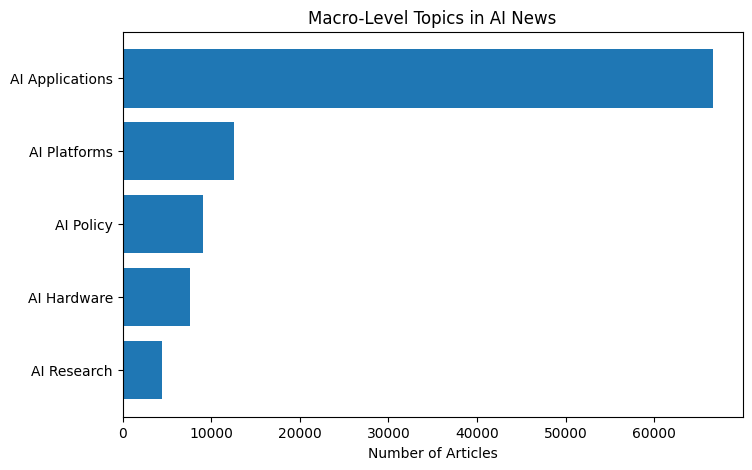

In [18]:
df["macro_topic"] = df["topic_label"].map(macro_topic_map)

macro_summary = (
    df.groupby("macro_topic")
    .size()
    .reset_index(name="doc_count")
    .sort_values("doc_count", ascending=False)
)

plt.figure(figsize=(8,5))
plt.barh(macro_summary["macro_topic"], macro_summary["doc_count"])
plt.gca().invert_yaxis()

plt.xlabel("Number of Articles")
plt.title("Macro-Level Topics in AI News")

plt.show()

The macro-level distribution shows that **AI Applications** dominate the news corpus by a large margin. Coverage of **AI Platforms** and **AI Policy** is also substantial, while **AI Hardware** and **AI Research** account for comparatively smaller portions of the dataset. This suggests that AI news coverage is primarily application-driven rather than purely research-focused.

### Industry distribution chart

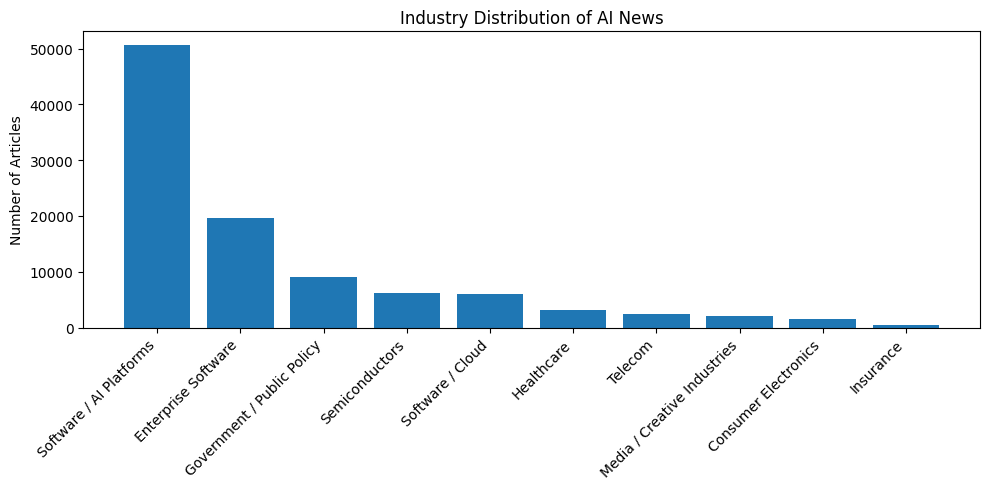

In [19]:
industry_summary = (
    topic_summary[topic_summary["topic_keep"] == 1]
    .groupby("industry")["doc_count"]
    .sum()
    .reset_index()
    .sort_values("doc_count", ascending=False)
)

plt.figure(figsize=(10,5))
plt.bar(industry_summary["industry"], industry_summary["doc_count"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("Number of Articles")
plt.title("Industry Distribution of AI News")
plt.tight_layout()
plt.show()

The industry-level distribution shows that AI-related news is most concentrated in **software and platform-oriented sectors**, followed by **enterprise software**, **government/public policy**, and **semiconductors**. This suggests that public AI discourse is strongly centered on software ecosystems, enterprise adoption, and regulation.

### Topic share pie chart

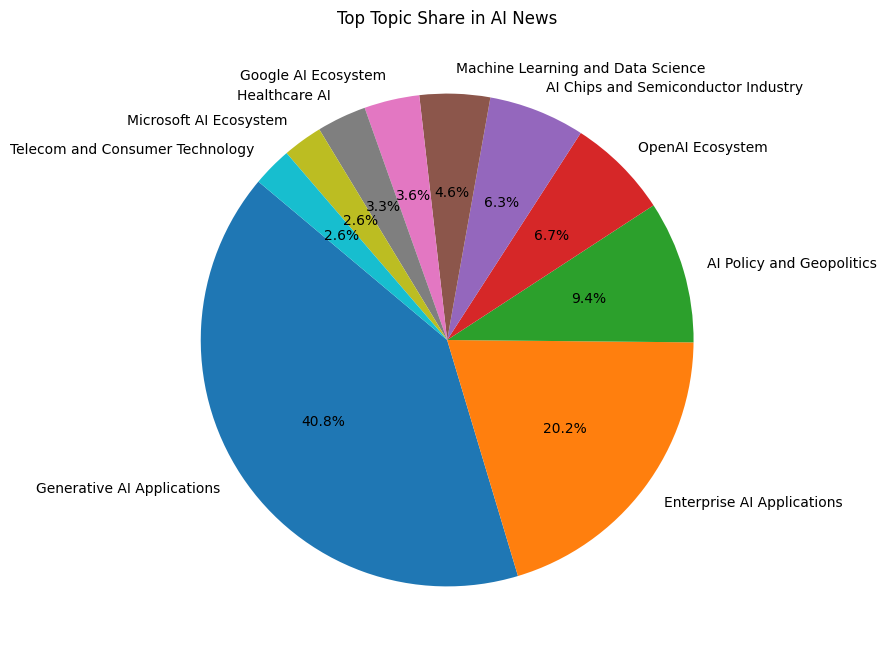

In [21]:
plot_df = (
    topic_summary[topic_summary["topic_keep"] == 1]
    .sort_values("doc_count", ascending=False)
)

top10 = plot_df.head(10)

plt.figure(figsize=(8,8))
plt.pie(
    top10["doc_count"],
    labels=top10["topic_label"],
    autopct="%1.1f%%",
    startangle=140
)

plt.title("Top Topic Share in AI News")
plt.show()

The pie chart confirms that **Generative AI Applications** represent the largest share of retained topics, followed by **Enterprise AI Applications** and **AI Policy and Geopolitics**. Together, these topics account for a substantial portion of the corpus, indicating that practical adoption, business use cases, and policy concerns dominate current AI news coverage.

### Export outputs

In [ ]:
doc_topics = df[[
    "date",
    "domain",
    "title",
    "topic_id",
    "topic_label",
    "industry",
    "topic_keep",
    "macro_topic"
]].copy()

doc_topics.to_parquet("doc_topics.parquet", index=False)

# topic summary
topic_summary.to_csv("topic_summary.csv", index=False)

# industry summary
industry_summary.to_csv("industry_summary.csv", index=False)

# macro topic summary
macro_summary.to_csv("macro_topic_summary.csv", index=False)

### Final checks

In [23]:
print("Stage C outputs saved:")
print("- doc_topics.parquet")
print("- topic_summary.csv")
print("- macro_topic_summary.csv")
print("- industry_summary.csv")

print("\nValid topics kept:", topic_summary["topic_keep"].sum())
print("Macro topics:", macro_summary.shape[0])
print("Documents with macro topic:", df["macro_topic"].notna().sum())

Stage C outputs saved:
- doc_topics.parquet
- topic_summary.csv
- macro_topic_summary.csv
- industry_summary.csv

Valid topics kept: 14
Macro topics: 5
Documents with macro topic: 100352


In [24]:
print(df["topic_label"].isna().sum())
print(df["industry"].isna().sum())
print(df["macro_topic"].isna().sum())

0
0
14654
